# Data understanding: PolarBearVidID

Explores the data produced by `preprocess.py`: the train/validation/test split CSVs in `data/splits/` and the frame embeddings in `data/polarbear_embeddings.npz`.

Runs locally in a few seconds. It does **not** need the 1.6 GB dataset or a GPU.

Each cell does one small step and shows its result, so you can inspect the data one piece at a time.

### TODO
The cameras are very uneven across bears. Bears 007 to 012 never appear on camera 03, and bear 010 is almost always on camera 02. If each camera shows a different background, the model may be partly recognizing the background or camera rather than the bear. That's a good point for your analysis, especially when checking which bears get confused with each other.
57 videos don't start at frame 0. Their numbering starts later, at 14 or 17 for example. I had assumed every video starts at 0 and fixed that. Measured from first frame to last, video lengths range from 28 to 100 frames, matching the counts in cs_117_project.ipynb. Most videos (1,242) are exactly 100 frames.

## 0. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

Run everything from the repo folder (one level up from `notebooks/`), so paths like `data/splits` work the same as in the `.py` files.

In [2]:
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
Path.cwd().name

'Polar-Bear-Vision-Project'

Paths to the files `preprocess.py` produced.

In [3]:
SPLITS_DIR = Path("data/splits")
EMBEDDINGS_PATH = Path("data/polarbear_embeddings.npz")
SPLITS = ["train", "validation", "test"]

Chart colors: one fixed color per split, used in every chart.

In [4]:
SPLIT_COLORS = {"train": "#2a78d6", "validation": "#eb6834", "test": "#1baf7a"}
BAR_COLOR = "#2a78d6"
SURFACE = "#fcfcfb"
TEXT = "#52514e"
GRID = "#e4e3df"

Chart style: light background, gray text, faint horizontal grid only.

In [5]:
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": TEXT,
    "xtick.color": TEXT, "ytick.color": TEXT, "text.color": TEXT,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
    "figure.dpi": 110,
})

## 1. Load the split CSVs

Each CSV has one row per **sampled frame**. Start with train.

In [6]:
train = pd.read_csv(SPLITS_DIR / "train.csv", dtype={"identity": str})
train.head()

,filepath,identity,sequence,frame_number,member,split
0,000C01T000F000.jpg,000,000C01T000,0,PolarBearVidID/000/000C01T000F000.jpg,train
1,000C01T000F005.jpg,000,000C01T000,5,PolarBearVidID/000/000C01T000F005.jpg,train
2,000C01T000F010.jpg,000,000C01T000,10,PolarBearVidID/000/000C01T000F010.jpg,train
3,000C01T000F015.jpg,000,000C01T000,15,PolarBearVidID/000/000C01T000F015.jpg,train
4,000C01T000F020.jpg,000,000C01T000,20,PolarBearVidID/000/000C01T000F020.jpg,train


`dtype={"identity": str}` keeps bear IDs like `000` as text. Without it pandas would read them as the number `0`.

In [7]:
train.dtypes

filepath        object
identity        object
sequence        object
frame_number     int64
member          object
split           object
dtype: object

Load all three splits and stack them into one table, `df`.

In [8]:
df = pd.concat(
    [pd.read_csv(SPLITS_DIR / f"{s}.csv", dtype={"identity": str}) for s in SPLITS],
    ignore_index=True,
)
df.shape

(28620, 6)

In [9]:
df.sample(5, random_state=0)

,filepath,identity,sequence,frame_number,member,split
151,000C01T025F057.jpg,000,000C01T025,57,PolarBearVidID/000/000C01T025F057.jpg,train
26808,007C02T025F041.jpg,007,007C02T025,41,PolarBearVidID/007/007C02T025F041.jpg,test
28606,012C03T027F031.jpg,012,012C03T027,31,PolarBearVidID/012/012C03T027F031.jpg,test
13103,008C01T086F015.jpg,008,008C01T086,15,PolarBearVidID/008/008C01T086F015.jpg,train
12251,007C02T103F057.jpg,007,007C02T103,57,PolarBearVidID/007/007C02T103F057.jpg,train


Columns:
- `filepath`: filename only (despite the name)
- `identity`: which bear
- `sequence`: which video
- `frame_number`: which frame of that video
- `member`: full path to the image
- `split`: train / validation / test

## 2. The dataset at a glance

How many individual bears?

In [10]:
df["identity"].nunique()

13

How many videos?

In [11]:
df["sequence"].nunique()

1431

How many sampled frames in total?

In [12]:
len(df)

28620

Does every video have exactly 20 sampled frames? This counts how many videos have each frame count.

In [13]:
frames_per_video = df.groupby("sequence").size()
frames_per_video.value_counts()

20    1431
Name: count, dtype: int64

## 3. Videos and frames per bear

In [14]:
per_bear = df.groupby("identity").agg(
    videos=("sequence", "nunique"),
    sampled_frames=("sequence", "size"),
)
per_bear

,videos,sampled_frames
identity,,
000,123,2460
001,105,2100
002,108,2160
003,118,2360
004,104,2080
005,107,2140
006,107,2140
007,104,2080
008,120,2400


Summary of videos per bear: how balanced are the bears?

In [15]:
per_bear["videos"].describe()

count     13.000000
mean     110.076923
std        7.488453
min      100.000000
25%      104.000000
50%      107.000000
75%      118.000000
max      123.000000
Name: videos, dtype: float64

Videos per bear as a chart.

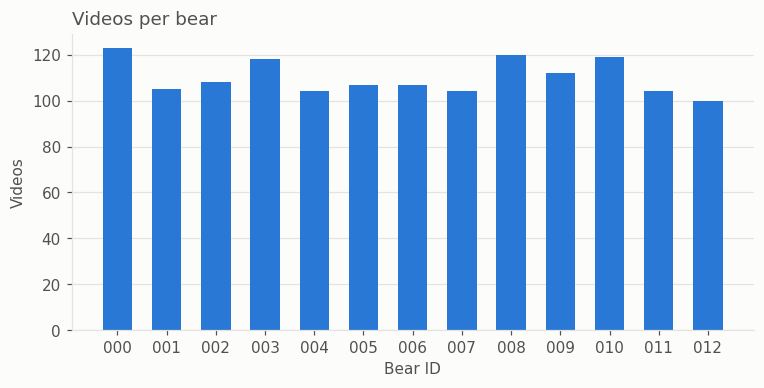

In [16]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(per_bear.index, per_bear["videos"], color=BAR_COLOR, width=0.6)
ax.set_title("Videos per bear", loc="left")
ax.set_xlabel("Bear ID")
ax.set_ylabel("Videos")
plt.show()

## 4. Train / validation / test split

The split is done **per video**, so first make a table with one row per video.

In [17]:
videos = df.drop_duplicates(["identity", "sequence"])[["identity", "sequence", "split"]]
videos.shape

(1431, 3)

Videos in each split overall. Expected: 1,001 / 215 / 215.

In [18]:
videos["split"].value_counts().reindex(SPLITS)

split
train         1001
validation     215
test           215
Name: count, dtype: int64

Videos in each split, **per bear**.

In [19]:
split_counts = pd.crosstab(videos["identity"], videos["split"])[SPLITS]
split_counts

split,train,validation,test
identity,,,
000,86,18,19
001,73,16,16
002,76,16,16
003,82,18,18
004,73,16,15
005,75,16,16
006,75,16,16
007,73,16,15
008,84,18,18


The same as fractions of each bear's videos. Because the split is stratified, every bear should be close to 0.70 / 0.15 / 0.15.

In [20]:
split_share = pd.crosstab(videos["identity"], videos["split"], normalize="index")[SPLITS]
split_share.round(3)

split,train,validation,test
identity,,,
000,0.699,0.146,0.154
001,0.695,0.152,0.152
002,0.704,0.148,0.148
003,0.695,0.153,0.153
004,0.702,0.154,0.144
005,0.701,0.150,0.150
006,0.701,0.150,0.150
007,0.702,0.154,0.144
008,0.700,0.150,0.150


Split share per bear as a chart. Each bar is one bear, adding up to 100%.

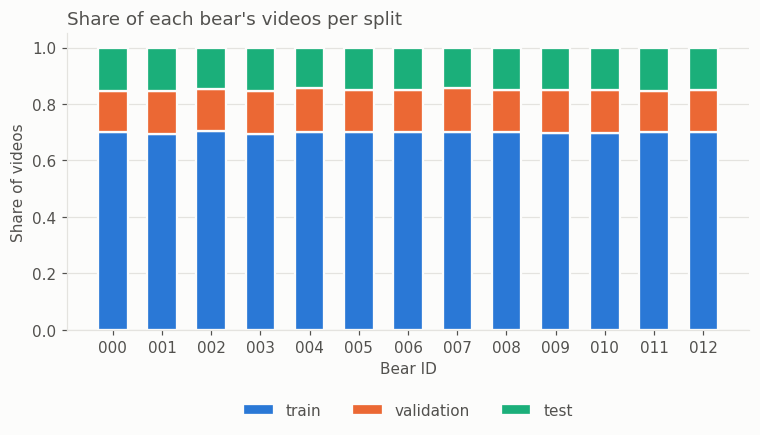

In [21]:
fig, ax = plt.subplots(figsize=(8, 3.5))
bottom = np.zeros(len(split_share))
for s in SPLITS:
    ax.bar(split_share.index, split_share[s], bottom=bottom, label=s,
           color=SPLIT_COLORS[s], width=0.6, edgecolor=SURFACE, linewidth=1.5)
    bottom += split_share[s].to_numpy()
ax.set_title("Share of each bear's videos per split", loc="left")
ax.set_xlabel("Bear ID")
ax.set_ylabel("Share of videos")
ax.legend(ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.show()

## 5. Leakage check

No video should appear in more than one split. If one did, the model could be tested on frames from a video it was trained on.

In [22]:
splits_per_video = df.groupby("sequence")["split"].nunique()
splits_per_video.value_counts()

split
1    1431
Name: count, dtype: int64

In [23]:
assert (splits_per_video == 1).all(), "Some videos appear in more than one split!"
"No leakage: every video is in exactly one split"

'No leakage: every video is in exactly one split'

## 6. What the sequence name contains

A sequence name like `000C01T038` has three parts: bear `000`, `C01`, and `T038`. `C` and `T` most likely mean **camera** and **track** (inferred from the names, not confirmed by the dataset docs).

In [24]:
parts = videos["sequence"].str.extract(r"(?P<bear>\d{3})C(?P<camera>\d+)T(?P<track>\d+)")
parts.head()

,bear,camera,track
0,000,01,000
20,000,01,009
40,000,01,010
60,000,01,012
80,000,01,015


Does the bear ID in the name always match the `identity` column?

In [25]:
(parts["bear"] == videos["identity"]).all()

np.True_

How many videos come from each camera, per bear?

In [26]:
pd.crosstab(videos["identity"], parts["camera"])

camera,01,02,03
identity,,,
000,48,32,43
001,65,8,32
002,53,46,9
003,63,29,26
004,69,21,14
005,57,42,8
006,51,55,1
007,34,70,0
008,81,39,0


**Worth noticing:** the cameras are very uneven across bears. Bears `007` to `012` never appear on camera 03, and some bears are mostly on one camera (e.g. `010` on camera 02). If each camera sees a different background, the model could partly be recognizing the *camera or background* rather than the bear. That's worth keeping in mind when analyzing results.

## 7. Which frames were sampled

`build_manifest_and_sample` picked 20 evenly spaced frames from each video. Look at one video first.

In [27]:
first_video = df["sequence"].iloc[0]
df.loc[df["sequence"] == first_video, "frame_number"].sort_values().tolist()

[0, 5, 10, 15, 20, 26, 31, 36, 41, 46, 52, 57, 62, 67, 72, 78, 83, 88, 93, 99]

Gap between consecutive sampled frames, across all videos. Gaps of 5 or 6 mean a video of about 100 frames.

In [28]:
gaps = (
    df.sort_values(["sequence", "frame_number"])
      .groupby("sequence")["frame_number"]
      .diff()
      .dropna()
)
gaps.value_counts().sort_index()

frame_number
1.0       13
2.0      181
3.0      928
4.0     1557
5.0    19515
6.0     4995
Name: count, dtype: int64

Sampling always includes a video's first and last frame. What frame number does each video start at?

In [29]:
first_frame = df.groupby("sequence")["frame_number"].min()
(first_frame == 0).value_counts()

frame_number
True     1374
False      57
Name: count, dtype: int64

Most videos start at frame 0, but some don't: their frame numbering starts later. Look at a few of them.

In [30]:
first_frame[first_frame > 0].head(10)

sequence
000C01T030    17
000C01T036    14
000C01T063    10
000C02T048    12
000C02T096    14
000C03T002    15
000C03T007    12
000C03T034     9
000C03T079    16
000C03T103     9
Name: frame_number, dtype: int64

Span of each video: from its first frame number to its last. This is the video length if no frame numbers are skipped, so treat it as an estimate.

In [31]:
span = df.groupby("sequence")["frame_number"].agg(["min", "max"])
span["length"] = span["max"] - span["min"] + 1
span["length"].describe()

count    1431.000000
mean       96.689727
std         9.980199
min        28.000000
25%       100.000000
50%       100.000000
75%       100.000000
max       100.000000
Name: length, dtype: float64

How many videos have each length? Most are exactly 100 frames.

In [32]:
span["length"].value_counts().head(10)

length
100    1242
71       10
86        9
70        8
69        7
85        7
90        6
63        6
65        6
87        6
Name: count, dtype: int64

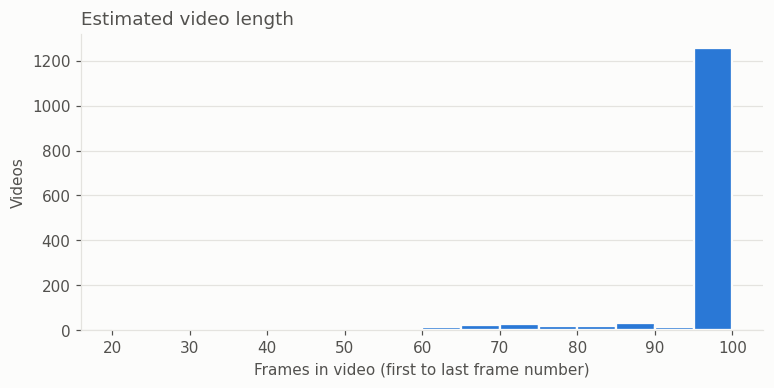

In [33]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(span["length"], bins=range(20, 105, 5), color=BAR_COLOR, edgecolor=SURFACE, linewidth=1.5)
ax.set_title("Estimated video length", loc="left")
ax.set_xlabel("Frames in video (first to last frame number)")
ax.set_ylabel("Videos")
plt.show()

## 8. The embeddings file

`polarbear_embeddings.npz` holds one 768-number MegaDescriptor vector per sampled frame, plus labels. See what's inside.

In [34]:
emb = np.load(EMBEDDINGS_PATH)
emb.files

['embeddings', 'member', 'identity', 'sequence', 'split']

In [35]:
{name: emb[name].shape for name in emb.files}

{'embeddings': (28620, 768),
 'member': (28620,),
 'identity': (28620,),
 'sequence': (28620,),
 'split': (28620,)}

One row per sampled frame, so it should have 28,620 rows, the same as the CSVs.

In [36]:
emb["embeddings"].shape[0] == len(df)

True

Do the npz labels cover exactly the same images as the CSVs?

In [37]:
set(emb["member"]) == set(df["member"])

True

Check one image: does the npz agree with the CSV on its bear and split?

In [38]:
labels = pd.DataFrame({k: emb[k] for k in ["member", "identity", "sequence", "split"]})
check = labels.merge(df, on="member", suffixes=("_npz", "_csv"))
(check["identity_npz"] == check["identity_csv"]).all(), (check["split_npz"] == check["split_csv"]).all()

(np.True_, np.True_)

First few numbers of the first frame's embedding.

In [39]:
emb["embeddings"][0][:10]

array([-0.40424168,  0.97166246, -0.82638824, -0.14623933,  1.443716  ,
       -0.0590067 ,  0.63331723, -1.0359333 , -1.216118  ,  1.0406536 ],
      dtype=float32)

Length (norm) of each embedding vector. `core_objective.py` normalizes the *video averages* to length 1, so the raw frame vectors don't need to be length 1 here.

In [40]:
norms = np.linalg.norm(emb["embeddings"], axis=1)
pd.Series(norms).describe()

count    28620.000000
mean        18.455757
std          5.752014
min          5.639006
25%         14.165888
50%         17.532097
75%         21.770670
max         41.788731
dtype: float64